# Fase 1 — Construcción de datos funcionales paso a paso

**Ítem 1 de la rúbrica (10 %).** Para obtener 5 se pide:

1. matriz de la base **Φ** y coeficientes por **mínimos cuadrados programados paso a paso, sin librerías**;
2. selección de **K** con **ECM, VC y VCG**: gráfica y valor elegido **para cada fuente**;
3. verificación numérica de la matriz de suavizado: **S idempotente y tr(S) = K**;
4. **covarianza residual** y **bandas de confianza punto a punto**, interpretadas como punto a punto;
5. curvas de ambas fuentes (diaria y péntada) **sobre el mismo dominio anual**.

Aquí todo se programa con `numpy` (álgebra matricial). La base B‑spline se construye con la recursión de Cox–de Boor escrita a mano. Las librerías (`scipy`) solo se usan para **verificar** que la base programada es correcta. Se sigue la metodología del script de clase *Construcción de datos funcionales* (Φ, `y2cMap`, H, ECM/VC/VCG, σ² y bandas ±2 EE).

**Entradas** (del notebook 01): los pares estación‑año que pasaron el criterio de cobertura (`eda_fase0/pares_estacion_anio_validos_preliminar.csv`), con los días marcados como erróneos convertidos en faltantes (`eda_fase0/dias_marcados.csv`), y el satélite entregado.

In [1]:
# %pip install pandas numpy matplotlib rasterio scipy
from pathlib import Path
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
ROOT = Path.cwd(); E0 = ROOT / "eda_fase0"; SAT_DIR = ROOT / "ImagenesSatelitePentadal"
OUT = ROOT / "fda_fase1"; OUT.mkdir(exist_ok=True)
RANGO = (1, 365)        # dominio anual común: día del año (año de 365 días)
ORDEN = 4               # B‑splines cúbicos: curvas suaves con 1.ª y 2.ª derivada continuas (necesarias en la fase 2)

## 1. Dominio anual común y unidades

Las dos fuentes deben vivir en **el mismo dominio**: el día del año, t ∈ [1, 365].

- **Estaciones (diario).** Cada día es un punto tᵢ = 1, …, 365. El **29 de febrero se elimina** en los años bisiestos y los días siguientes se numeran como en un año normal. Así todos los años tienen la misma rejilla y el 1 de marzo es siempre el día 60.
- **Satélite (péntada).** Cada péntada se ubica en el **día central** de su intervalo (1–5, 6–10, 11–15, 16–20, 21–25 y 26–fin de mes). Su valor se divide por el número real de días (3 a 6) para pasar a **mm/día**: el EDA mostró que, sin esto, la 6.ª péntada de los meses de 31 días aparece artificialmente más lluviosa.
- **Escala: mm/día.** El suavizado por mínimos cuadrados es lineal, así que la curva estima la **tasa media de lluvia** alrededor de cada día, y esa cantidad es la misma en las dos fuentes: el promedio de 5 días del satélite es justamente una tasa media. Si se transformara antes (√P o log(1+P)), las fuentes dejarían de ser comparables: la raíz de un promedio de 5 días es mayor que el promedio de las raíces diarias, y la lluvia diaria es intermitente (muchos ceros). La diferencia entre fuentes sería en parte un artefacto de la transformación (se muestra en la §4). La transformación √ que pide la red (fase 4) se aplica **después**, sobre las curvas ya suavizadas.
- **Periodo del proyecto: 1981–2003** (fe de erratas del enunciado). Se usan las péntadas satelitales de esos 23 años; 2004–2013 quedan fuera. Partición temporal: entrenamiento 1981–1995, validación 1996–2000 y prueba 2001–2003.

In [2]:
# ---- Estaciones: matriz de curvas (estación‑año) x 365 días, con NaN donde falta el dato
raw = pd.read_pickle(E0 / "estaciones_crudas.pkl")
val = pd.read_csv(E0 / "pares_estacion_anio_validos_preliminar.csv")
flags = pd.read_csv(E0 / "dias_marcados.csv", parse_dates=["DATE"])
x = raw.merge(val[["STATION_ID", "YEAR"]], on=["STATION_ID", "YEAR"])
x["DATE"] = pd.to_datetime(dict(year=x.YEAR, month=x.MONTH, day=x.DAY))
x = x.merge(flags, on=["STATION_ID", "DATE"], how="left")
x.loc[x.flag.notna(), "VALUE"] = np.nan                       # días erróneos -> faltantes
x = x[~((x.MONTH == 2) & (x.DAY == 29))]                      # se elimina el 29 de febrero
x["t"] = pd.to_datetime(dict(year=2001, month=x.MONTH, day=x.DAY)).dt.dayofyear
Y_mm = (x.pivot_table(index=["STATION_ID", "YEAR"], columns="t", values="VALUE", aggfunc="first")
          .reindex(columns=range(1, 366)).reindex(pd.MultiIndex.from_frame(val[["STATION_ID", "YEAR"]])))
t_est = np.arange(1, 366, dtype=float)
completas = ~Y_mm.isna().any(axis=1)
print(f"Curvas de estaciones: {len(Y_mm)} (completas: {completas.sum()}, con algún faltante: {(~completas).sum()})")
print(f"Faltantes por curva incompleta: mediana {Y_mm[~completas].isna().sum(axis=1).median():.0f} días, máximo {Y_mm.isna().sum(axis=1).max()}")

C:\Users\Administrador\AppData\Local\Temp\ipykernel_13964\614611191.py:10: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  x["t"] = pd.to_datetime(dict(year=2001, month=x.MONTH, day=x.DAY)).dt.dayofyear


Curvas de estaciones: 4494 (completas: 3813, con algún faltante: 681)
Faltantes por curva incompleta: mediana 3 días, máximo 35


In [3]:
# ---- Satélite: matriz de curvas (año, píxel) x 72 péntadas, en mm/día, ubicadas en el día central
tifs = sorted(p for p in SAT_DIR.glob("ppt*.tif") if not p.name.startswith("._"))
an = np.array([int(p.stem[3:7]) for p in tifs]); pe = np.array([int(p.stem[7:9]) for p in tifs])
sel = (an >= 1981) & (an <= 2003)                 # periodo del proyecto
cubo = np.stack([rasterio.open(p).read(1) for p, s in zip(tifs, sel) if s]).astype(float)
an, pe = an[sel], pe[sel]
mes, k = (pe - 1) // 6 + 1, (pe - 1) % 6
dias = np.where(k < 5, 5, [pd.Timestamp(a, m, 1).days_in_month - 25 for a, m in zip(an, mes)])
cubo_dia = cubo / dias[:, None, None]

# día central de cada péntada en un año de 365 días
mes72, k72 = np.arange(72) // 6 + 1, np.arange(72) % 6
ini = 5 * k72 + 1
fin = np.where(k72 < 5, 5 * k72 + 5, [pd.Timestamp(2001, m, 1).days_in_month for m in mes72])
t_sat = np.array([pd.Timestamp(2001, m, 1).dayofyear - 1 for m in mes72]) + (ini + fin) / 2

n_an = len(np.unique(an)); H_, W_ = cubo.shape[1:]
X_mm = cubo_dia.reshape(n_an, 72, H_, W_).transpose(0, 2, 3, 1).reshape(-1, 72)
idx_sat = pd.MultiIndex.from_product([np.unique(an), range(H_), range(W_)], names=["anio", "fila", "col"])
print(f"Curvas satelitales: {X_mm.shape[0]} = {n_an} años x {H_*W_} píxeles; {X_mm.shape[1]} puntos por curva")
print("Centros de péntada (primeros):", t_sat[:7], "... último:", t_sat[-1])

Y, X = Y_mm.values, X_mm                         # escala de trabajo: mm/día
Ys, Xs = np.sqrt(Y), np.sqrt(X)                  # solo para el análisis de sensibilidad de la §4

Curvas satelitales: 33189 = 23 años x 1443 píxeles; 72 puntos por curva
Centros de péntada (primeros): [ 3.   8.  13.  18.  23.  28.5 34. ] ... último: 362.5


C:\Users\Administrador\AppData\Local\Temp\ipykernel_13964\1388770697.py:15: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  t_sat = np.array([pd.Timestamp(2001, m, 1).dayofyear - 1 for m in mes72]) + (ini + fin) / 2


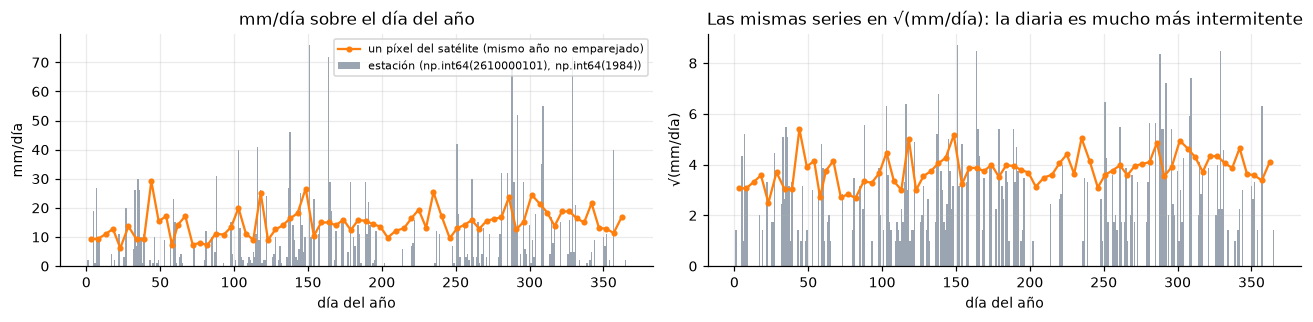

In [4]:
# Ejemplo: una estación‑año y un píxel‑año sobre el mismo dominio
i_ej = np.flatnonzero(completas.values)[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].bar(t_est, Y_mm.values[i_ej], width=1, color="#9aa5b1", label=f"estación {Y_mm.index[i_ej]}")
ax[0].plot(t_sat, X_mm[123], "o-", ms=3, color="C1", label="un píxel del satélite (mismo año no emparejado)")
ax[0].set(title="mm/día sobre el día del año", xlabel="día del año", ylabel="mm/día"); ax[0].legend(fontsize=7)
ax[1].bar(t_est, Ys[i_ej], width=1, color="#9aa5b1"); ax[1].plot(t_sat, Xs[123], "o-", ms=3, color="C1")
ax[1].set(title="Las mismas series en √(mm/día): la diaria es mucho más intermitente", xlabel="día del año", ylabel="√(mm/día)")
plt.tight_layout(); plt.show()

## 2. La base B‑spline programada paso a paso

Una base B‑spline de **orden m** (grado m−1) con **K** funciones sobre [a, b] se define con un vector de nodos: los extremos a y b repetidos m veces y K − m nodos interiores equiespaciados (igual que `create.bspline.basis(rangeval, nbasis = K, norder = m)` de clase). Las funciones se construyen con la **recursión de Cox–de Boor**:

$$B_{j,1}(t)=\mathbb{1}[\tau_j\le t<\tau_{j+1}],\qquad
B_{j,m}(t)=\frac{t-\tau_j}{\tau_{j+m-1}-\tau_j}B_{j,m-1}(t)+\frac{\tau_{j+m}-t}{\tau_{j+m}-\tau_{j+1}}B_{j+1,m-1}(t)$$

La matriz **Φ** (n × K) tiene en la fila i las K funciones evaluadas en tᵢ.

Φ: (365, 11) | suma de cada fila (partición de la unidad): 1.0 a 1.0


K= 6: max |Φ_propia − Φ_scipy| = 3.3e-16
K=11: max |Φ_propia − Φ_scipy| = 3.3e-16
K=17: max |Φ_propia − Φ_scipy| = 2.2e-16
K=40: max |Φ_propia − Φ_scipy| = 2.2e-16


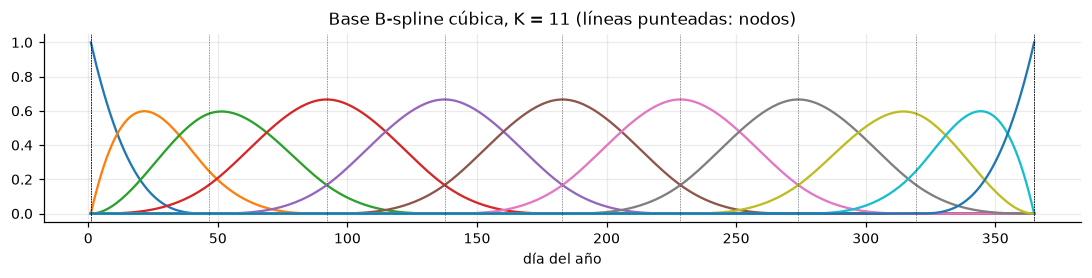

In [5]:
def nodos(rango, K, orden=ORDEN):
    a, b = rango
    interiores = np.linspace(a, b, K - orden + 2)[1:-1]
    return np.r_[[a] * orden, interiores, [b] * orden]

def base_bspline(t, rango, K, orden=ORDEN):
    # Matriz Φ (len(t) x K) por la recursión de Cox–de Boor
    t = np.asarray(t, float); tau = nodos(rango, K, orden)
    B = np.zeros((len(t), len(tau) - 1))
    for j in range(len(tau) - 1):                                  # orden 1: indicadoras
        B[:, j] = (t >= tau[j]) & (t < tau[j + 1])
    ultimo = np.max(np.flatnonzero(tau[:-1] < tau[1:]))
    B[t == rango[1], ultimo] = 1                                   # incluye el extremo derecho
    for m in range(2, orden + 1):                                  # sube el orden
        Bn = np.zeros((len(t), len(tau) - m))
        for j in range(len(tau) - m):
            d1, d2 = tau[j + m - 1] - tau[j], tau[j + m] - tau[j + 1]
            izq = (t - tau[j]) / d1 * B[:, j] if d1 > 0 else 0
            der = (tau[j + m] - t) / d2 * B[:, j + 1] if d2 > 0 else 0
            Bn[:, j] = izq + der
        B = Bn
    return B

Phi = base_bspline(t_est, RANGO, 11)
print("Φ:", Phi.shape, "| suma de cada fila (partición de la unidad):", Phi.sum(1).min().round(12), "a", Phi.sum(1).max().round(12))

# Verificación (solo comprobación) contra la implementación de scipy
from scipy.interpolate import BSpline
for K in [6, 11, 17, 40]:
    ref = BSpline.design_matrix(t_est, nodos(RANGO, K), ORDEN - 1).toarray()
    print(f"K={K:2d}: max |Φ_propia − Φ_scipy| = {np.abs(base_bspline(t_est, RANGO, K) - ref).max():.1e}")

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(t_est, Phi); [ax.axvline(v, c="k", lw=.4, ls=":") for v in nodos(RANGO, 11)]
ax.set(title="Base B‑spline cúbica, K = 11 (líneas punteadas: nodos)", xlabel="día del año"); plt.tight_layout(); plt.show()

## 3. Mínimos cuadrados paso a paso y matriz de suavizado

Para cada curva con observaciones y = (y₁, …, yₙ):

$$\hat{c}=(\Phi^\top\Phi)^{-1}\Phi^\top y = C\,y,\qquad \hat{y}=\Phi\hat{c}=H\,y,\qquad H=\Phi(\Phi^\top\Phi)^{-1}\Phi^\top$$

C es el `y2cMap` de clase. H (o S) es una **proyección**: simétrica, idempotente (H² = H) y con **tr(H) = K** (grados de libertad). Se verifica numéricamente en ambas fuentes.

**Curvas con días faltantes:** se usan solo las filas observadas, Φ₍ₒ₎. Cada una de esas curvas tiene su propia H₍ₒ₎ (n₍ₒ₎ × n₍ₒ₎), con traza K. No se imputa nada: la base reconstruye la curva en los huecos a partir de los días vecinos.

In [6]:
def ajuste_mco(y, Phi):
    # Coeficientes, matriz C (y2cMap) y H para una curva (usa solo los puntos observados)
    m = ~np.isnan(y); P = Phi[m]
    C = np.linalg.solve(P.T @ P, P.T)          # (ΦᵀΦ)⁻¹Φᵀ, resolviendo el sistema (sin invertir explícitamente)
    return C @ y[m], C, P @ C, m

def verificar_H(H, K, nombre):
    print(f"{nombre}: simétrica {np.abs(H - H.T).max():.1e} | idempotente max|H²−H| = {np.abs(H @ H - H).max():.1e} "
          f"| tr(H) = {np.trace(H):.10f} (K = {K})")

K_demo = 11
for nombre, y, tt in [("Estación completa", Y[i_ej], t_est), ("Estación con faltantes", Y[np.flatnonzero(~completas.values)[0]], t_est),
                      ("Píxel satelital", X[0], t_sat)]:
    c, C, H, m = ajuste_mco(y, base_bspline(tt, RANGO, K_demo))
    verificar_H(H, K_demo, f"{nombre:24s} (n={m.sum()})")
    c_ref = np.linalg.lstsq(base_bspline(tt, RANGO, K_demo)[m], y[m], rcond=None)[0]
    print(f"{'':26s}coeficientes vs lstsq: {np.abs(c - c_ref).max():.1e}")

Estación completa        (n=365): simétrica 5.6e-17 | idempotente max|H²−H| = 2.5e-16 | tr(H) = 11.0000000000 (K = 11)
                          coeficientes vs lstsq: 2.5e-14
Estación con faltantes   (n=360): simétrica 5.6e-17 | idempotente max|H²−H| = 2.5e-16 | tr(H) = 11.0000000000 (K = 11)
                          coeficientes vs lstsq: 2.8e-14
Píxel satelital          (n=72): simétrica 1.1e-16 | idempotente max|H²−H| = 2.2e-16 | tr(H) = 11.0000000000 (K = 11)
                          coeficientes vs lstsq: 7.5e-14


## 4. Selección de K: ECM, VC y VCG

Para cada K se calculan sobre **todas las curvas de la fuente**, igual que en el script de clase:

- **ECM de ajuste** = media de (yᵢ − ŷᵢ)². Siempre baja al crecer K, así que no sirve para elegir.
- **VC (validación cruzada, dejar uno por fuera)** con el atajo de la diagonal de H: $\frac1n\sum_i\left(\frac{y_i-\hat y_i}{1-h_{ii}}\right)^2$, promediado sobre las curvas. Se verifica contra los n ajustes de fuerza bruta.
- **VCG** = $\frac{n\,\mathrm{SSE}}{(n-K)^2}$ por curva, sumada sobre las curvas.

**Sin fuga de información:** elegir K es una decisión del preprocesamiento, así que la selección se hace **solo con curvas de entrenamiento (1981–1995)** de cada fuente. El K elegido se aplica después a todas las curvas, incluidas las de validación y prueba.

En las estaciones la selección se hace con las **curvas completas** de entrenamiento. Con huecos de hasta 30 días y K grande, algunas funciones base quedan sin datos (ΦᵀΦ singular) y la VC se indefine. Después se comprueba que el K elegido sea estimable en todas las curvas con huecos.

In [7]:
def criterios(Ymat, t, Ks):
    # ECM, VC (atajo) y VCG por K para curvas sin faltantes, todo vectorizado sobre las curvas
    filas, n = [], len(t)
    for K in Ks:
        P = base_bspline(t, RANGO, K); C = np.linalg.solve(P.T @ P, P.T); H = P @ C; h = np.diag(H)
        E = Ymat - Ymat @ H.T
        filas.append({"K": K, "ECM": (E ** 2).mean(), "VC": ((E / (1 - h)) ** 2).mean(),
                      "VCG": (n * (E ** 2).sum(1) / (n - K) ** 2).sum()})
    return pd.DataFrame(filas)

# Verificación del atajo de VC contra dejar‑uno‑por‑fuera a la fuerza bruta (una estación‑año, K = 17)
y1 = Y[i_ej]; P = base_bspline(t_est, RANGO, 17); _, _, H, _ = ajuste_mco(y1, P)
vc_atajo = np.mean(((y1 - H @ y1) / (1 - np.diag(H))) ** 2)
pred = [P[j] @ np.linalg.solve(np.delete(P, j, 0).T @ np.delete(P, j, 0), np.delete(P, j, 0).T @ np.delete(y1, j)) for j in range(365)]
print(f"VC atajo = {vc_atajo:.8f} | VC dejar‑uno‑fuera = {np.mean((y1 - np.array(pred)) ** 2):.8f}")

VC atajo = 138.88528444 | VC dejar‑uno‑fuera = 138.88528444


In [8]:
t0 = time.time()
Ks_est, Ks_sat = list(range(4, 41)) + list(range(45, 101, 5)), list(range(4, 41))
ENTREN_FIN = 1995                                          # selección de K solo con entrenamiento (1981–1995)
ent_est = completas.values & (Y_mm.index.get_level_values("YEAR") <= ENTREN_FIN)
ent_sat = idx_sat.get_level_values("anio") <= ENTREN_FIN
print(f"Curvas de entrenamiento para elegir K — estaciones completas: {ent_est.sum()} | satélite: {ent_sat.sum()}")
Yc = Y[completas.values]
sel_est = criterios(Y[ent_est], t_est, Ks_est)             # mm/día (escala elegida)
sel_sat = criterios(X[ent_sat], t_sat, Ks_sat)
sel_est_r = criterios(Ys[ent_est], t_est, Ks_est)          # sensibilidad: √(mm/día)
sel_sat_r = criterios(Xs[ent_sat], t_sat, Ks_sat)
print(f"Tiempo: {time.time()-t0:.0f} s")

def elegido(df):
    return int(df.K[df.VC.idxmin()]), int(df.K[df.VCG.idxmin()])
resumen = pd.DataFrame({"fuente": ["Estaciones (diario)", "Satélite (péntada)"] * 2,
                        "escala": ["mm/día (elegida)"] * 2 + ["√(mm/día) (sensibilidad)"] * 2,
                        "K por VC": [elegido(d)[0] for d in [sel_est, sel_sat, sel_est_r, sel_sat_r]],
                        "K por VCG": [elegido(d)[1] for d in [sel_est, sel_sat, sel_est_r, sel_sat_r]]})
display(resumen)

Curvas de entrenamiento para elegir K — estaciones completas: 2626 | satélite: 21645


Tiempo: 4 s


,fuente,escala,K por VC,K por VCG
0,Estaciones (diario),mm/día (elegida),8,8
1,Satélite (péntada),mm/día (elegida),11,11
2,Estaciones (diario),√(mm/día) (sensibilidad),17,8
3,Satélite (péntada),√(mm/día) (sensibilidad),9,11


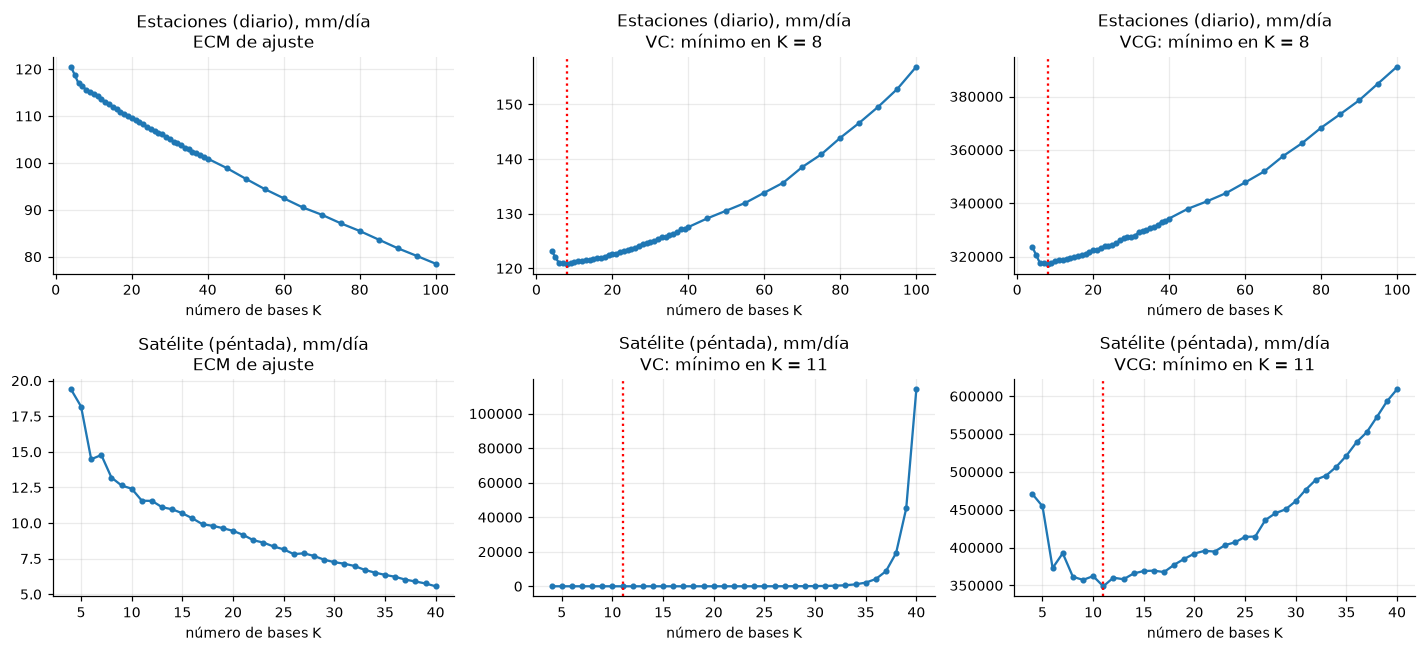

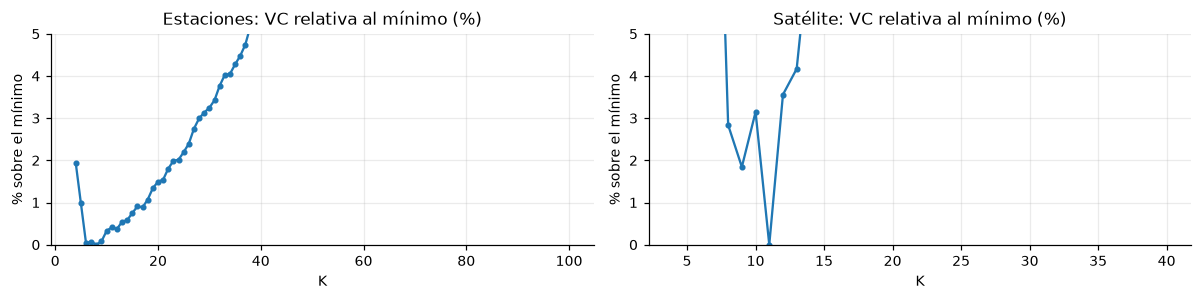

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for fila, (df, nom) in enumerate([(sel_est, "Estaciones (diario), mm/día"), (sel_sat, "Satélite (péntada), mm/día")]):
    kvc, kvcg = elegido(df)
    for a, crit in zip(ax[fila], ["ECM", "VC", "VCG"]):
        a.plot(df.K, df[crit], "o-", ms=3)
        if crit != "ECM":
            kk = kvc if crit == "VC" else kvcg
            a.axvline(kk, c="r", ls=":"); a.set_title(f"{nom}\n{crit}: mínimo en K = {kk}")
        else:
            a.set_title(f"{nom}\nECM de ajuste")
        a.set_xlabel("número de bases K")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for a, df, nom in [(ax[0], sel_est, "Estaciones"), (ax[1], sel_sat, "Satélite")]:
    a.plot(df.K, 100 * (df.VC / df.VC.min() - 1), "o-", ms=3); a.set_ylim(0, 5)
    a.set(title=f"{nom}: VC relativa al mínimo (%)", xlabel="K", ylabel="% sobre el mínimo")
plt.tight_layout(); plt.show()
sel_est.to_csv(OUT / "seleccion_K_estaciones.csv", index=False); sel_sat.to_csv(OUT / "seleccion_K_satelite.csv", index=False)

**Lectura de la selección de K.**

- El **ECM de ajuste** baja siempre con K (más bases = más ajuste, incluido el ruido), mientras la **VC** y la **VCG** tienen un mínimo interior. Es el compromiso sesgo‑varianza de clase.
- **Estaciones:** la lluvia diaria tiene un componente de ruido enorme (llueve o no, tormentas aisladas). La VC es **muy plana**: entre K ≈ 5 y K ≈ 17 cambia menos del 1 %. Los datos no distinguen bien entre esos valores, y los criterios se quedan con el más simple. Aun con K bajo, la curva capta los dos picos de lluvia (ver §7).
- **Satélite:** con 72 péntadas (ya promediadas en 5 días, mucho menos ruidosas) la VCG tiene un mínimo claro. Con K cercano a n = 72 la VC explota (h_ii → 1).
- **Sensibilidad a la escala:** en √(mm/día) los criterios eligen un K mayor para las estaciones (la raíz atenúa las tormentas, que dominan el error en mm). No se elige esa escala por la razón de la §1: haría incomparables las dos fuentes.
- **Elección:** **K de la VCG en mm/día** para cada fuente (el criterio usado en clase para las bandas). No hace falta el mismo K en ambas fuentes: las comparaciones de las fases siguientes se hacen evaluando las curvas en la misma rejilla de días.

In [10]:
K_EST, K_SAT = elegido(sel_est)[1], elegido(sel_sat)[1]
print(f"K elegido (VCG, mm/día) — estaciones: {K_EST} (nodos cada {364/(K_EST-ORDEN+1):.0f} días) | satélite: {K_SAT} (nodos cada {364/(K_SAT-ORDEN+1):.0f} días)")

Phi_est, Phi_sat = base_bspline(t_est, RANGO, K_EST), base_bspline(t_sat, RANGO, K_SAT)
# ¿El K elegido es estimable en las curvas con huecos?
cond = np.array([np.linalg.cond(Phi_est[~np.isnan(y)].T @ Phi_est[~np.isnan(y)]) for y in Y[~completas.values]])
print(f"Número de condición de ΦᵀΦ en curvas con huecos: mediana {np.median(cond):.0f}, máximo {cond.max():.0f} "
      f"(curva completa: {np.linalg.cond(Phi_est.T @ Phi_est):.0f}) -> todas estimables")

K elegido (VCG, mm/día) — estaciones: 8 (nodos cada 73 días) | satélite: 11 (nodos cada 46 días)
Número de condición de ΦᵀΦ en curvas con huecos: mediana 27, máximo 60 (curva completa: 27) -> todas estimables


## 5. Construcción de todas las curvas y verificación de S con el K elegido

In [11]:
# Estaciones: una sola H para las curvas completas y una H propia por curva con faltantes
C_est = np.linalg.solve(Phi_est.T @ Phi_est, Phi_est.T); H_est = Phi_est @ C_est
verificar_H(H_est, K_EST, "Estaciones, curvas completas")
coef_est = np.full((len(Y), K_EST), np.nan); sig2_est = np.full(len(Y), np.nan); traza = []
for i, y in enumerate(Y):
    c, C, H, m = ajuste_mco(y, Phi_est)
    coef_est[i] = c; e = y[m] - H @ y[m]; sig2_est[i] = (e ** 2).sum() / (m.sum() - K_EST)
    if not completas.values[i]: traza.append(np.trace(H))
print(f"Curvas con faltantes: tr(H₍ₒ₎) entre {min(traza):.10f} y {max(traza):.10f}")

# Satélite: todas completas -> una H
C_sat = np.linalg.solve(Phi_sat.T @ Phi_sat, Phi_sat.T); H_sat = Phi_sat @ C_sat
verificar_H(H_sat, K_SAT, "Satélite")
coef_sat = X @ C_sat.T
sig2_sat = ((X - X @ H_sat.T) ** 2).sum(1) / (72 - K_SAT)
print(f"Coeficientes: estaciones {coef_est.shape}, satélite {coef_sat.shape}")

Estaciones, curvas completas: simétrica 2.8e-17 | idempotente max|H²−H| = 1.5e-16 | tr(H) = 8.0000000000 (K = 8)


Curvas con faltantes: tr(H₍ₒ₎) entre 8.0000000000 y 8.0000000000
Satélite: simétrica 1.1e-16 | idempotente max|H²−H| = 2.2e-16 | tr(H) = 11.0000000000 (K = 11)
Coeficientes: estaciones (4494, 8), satélite (33189, 11)


Valores negativos (mm/día): estaciones 1.94 %, satélite 0.00 % de los puntos (mínimo -18.79 mm/día, en una estación muy lluviosa con un hueco). Se conservan en la construcción; en la fase 4 se truncan en 0 antes de aplicar √.


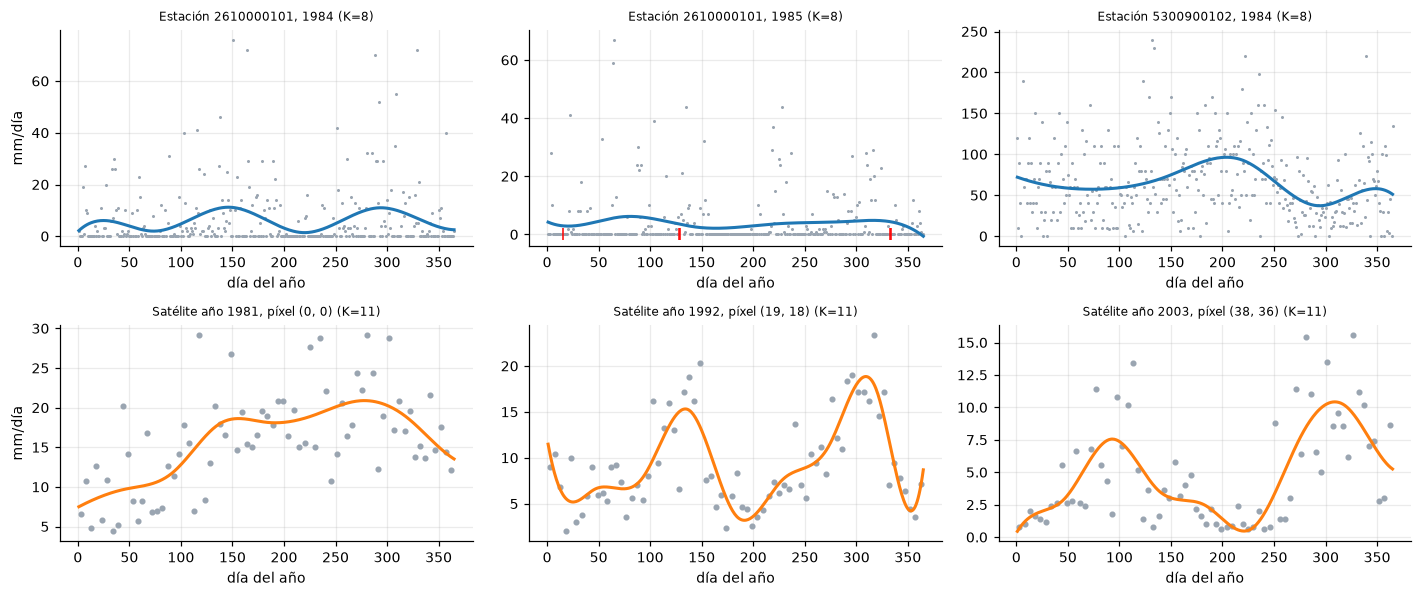

In [12]:
# Curvas reconstruidas sobre la rejilla diaria común
F_est = coef_est @ Phi_est.T                          # (curvas, 365)
F_sat = coef_sat @ base_bspline(t_est, RANGO, K_SAT).T
print(f"Valores negativos (mm/día): estaciones {100*(F_est < 0).mean():.2f} %, satélite {100*(F_sat < 0).mean():.2f} % de los puntos "
      f"(mínimo {F_est.min():.2f} mm/día, en una estación muy lluviosa con un hueco). Se conservan en la construcción; en la fase 4 se truncan en 0 antes de aplicar √.")

fig, ax = plt.subplots(2, 3, figsize=(13, 5.5))
ej_est = [i_ej, np.flatnonzero(~completas.values)[0], int(np.argmax(np.nanmean(Y, 1)))]
for a, i in zip(ax[0], ej_est):
    a.plot(t_est, Y[i], ".", ms=2, c="#9aa5b1"); a.plot(t_est, F_est[i], c="C0", lw=2)
    falt = np.isnan(Y[i]); a.plot(t_est[falt], np.zeros(falt.sum()), "|", c="red", ms=8)
    a.set_title(f"Estación {Y_mm.index[i][0]}, {Y_mm.index[i][1]} (K={K_EST})", fontsize=8)
for a, i in zip(ax[1], [0, len(X) // 2, len(X) - 1]):
    a.plot(t_sat, X[i], "o", ms=3, c="#9aa5b1"); a.plot(t_est, F_sat[i], c="C1", lw=2)
    a.set_title(f"Satélite año {idx_sat[i][0]}, píxel {idx_sat[i][1:]} (K={K_SAT})", fontsize=8)
for a in ax.ravel(): a.set_xlabel("día del año")
ax[0, 0].set_ylabel("mm/día"); ax[1, 0].set_ylabel("mm/día")
plt.tight_layout(); plt.show()

## 6. Covarianza residual y bandas de confianza punto a punto

**Varianza de la curva estimada.** Bajo el supuesto de clase, errores independientes con varianza constante, Var(y) = σ²I:

$$\widehat{\mathrm{Var}}[\hat y]=\hat\sigma^2\,\Phi C C^\top\Phi^\top,\qquad \hat\sigma^2=\frac{\mathrm{SSE}}{n-K}$$

y la banda es ŷ(t) ± 2·EE(t).

**Covarianza residual.** El supuesto σ²I se revisa con la **matriz de covarianza de los residuos entre curvas**, Σₑ(s, t), estimada con todas las curvas completas. Si Σₑ no es aproximadamente diagonal y constante (por ejemplo, si los residuos son más grandes en temporada de lluvias), la versión general es

$$\widehat{\mathrm{Var}}[\hat y]=\Phi C\,\Sigma\,C^\top\Phi^\top,\qquad \Sigma=\mathrm{diag}\big(\hat\sigma^2(t_1),\dots,\hat\sigma^2(t_n)\big).$$

Detalle técnico: no se puede usar directamente la matriz de covarianza de los **residuos**, porque los residuos son ortogonales a la base (C(I − H) = 0) y daría una varianza nula. Si la correlación residual entre días es pequeña, se usa su diagonal: la varianza del error en cada día, estimada con todas las curvas como media de eᵢ(t)² / (1 − h_tt). Como las curvas tienen niveles de ruido muy distintos (una estación del Pacífico frente a una del valle), de esa estimación se toma solo la **forma estacional**, y se escala al σ̂² propio de cada curva: σ̂ᵢ²(t) = σ̂ᵢ² · v(t)/v̄.

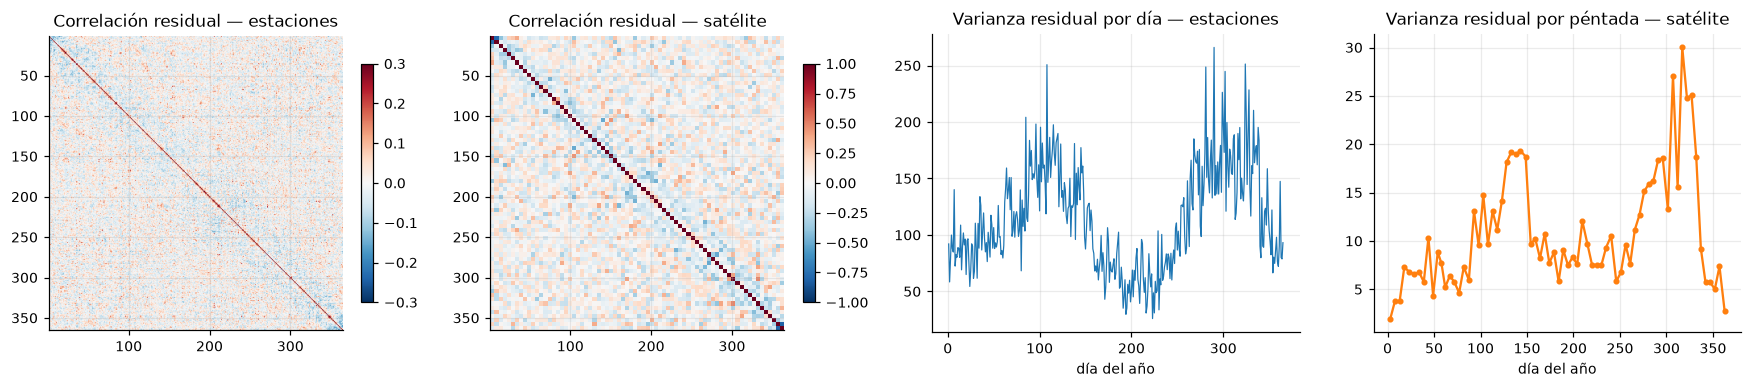

|correlación residual| fuera de la diagonal — estaciones: media 0.039, lag 1 día 0.075 | satélite: media 0.125, lag 1 péntada -0.071
Varianza residual estaciones: mín 25.96 (día 223), máx 266.05 (día 290)


In [13]:
Res_est = Yc - Yc @ H_est.T                      # residuos de las curvas completas (curvas x 365)
Res_sat = X - X @ H_sat.T
Se_est, Se_sat = np.cov(Res_est, rowvar=False), np.cov(Res_sat, rowvar=False)
def a_corr(S): d = np.sqrt(np.diag(S)); return S / np.outer(d, d)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
im = ax[0].imshow(a_corr(Se_est), cmap="RdBu_r", vmin=-.3, vmax=.3, extent=[1, 365, 365, 1])
ax[0].set_title("Correlación residual — estaciones"); plt.colorbar(im, ax=ax[0], shrink=.8)
im = ax[1].imshow(a_corr(Se_sat), cmap="RdBu_r", vmin=-1, vmax=1, extent=[1, 365, 365, 1])
ax[1].set_title("Correlación residual — satélite"); plt.colorbar(im, ax=ax[1], shrink=.8)
ax[2].plot(t_est, np.diag(Se_est), lw=.8); ax[2].set(title="Varianza residual por día — estaciones", xlabel="día del año")
ax[3].plot(t_sat, np.diag(Se_sat), "o-", ms=3, c="C1"); ax[3].set(title="Varianza residual por péntada — satélite", xlabel="día del año")
plt.tight_layout(); plt.show()

off = lambda S: np.abs(a_corr(S)[~np.eye(len(S), dtype=bool)])
print(f"|correlación residual| fuera de la diagonal — estaciones: media {off(Se_est).mean():.3f}, "
      f"lag 1 día {np.mean(np.diag(a_corr(Se_est), 1)):.3f} | satélite: media {off(Se_sat).mean():.3f}, lag 1 péntada {np.mean(np.diag(a_corr(Se_sat), 1)):.3f}")
v = np.diag(Se_est); print(f"Varianza residual estaciones: mín {v.min():.2f} (día {v.argmin()+1}), máx {v.max():.2f} (día {v.argmax()+1})")

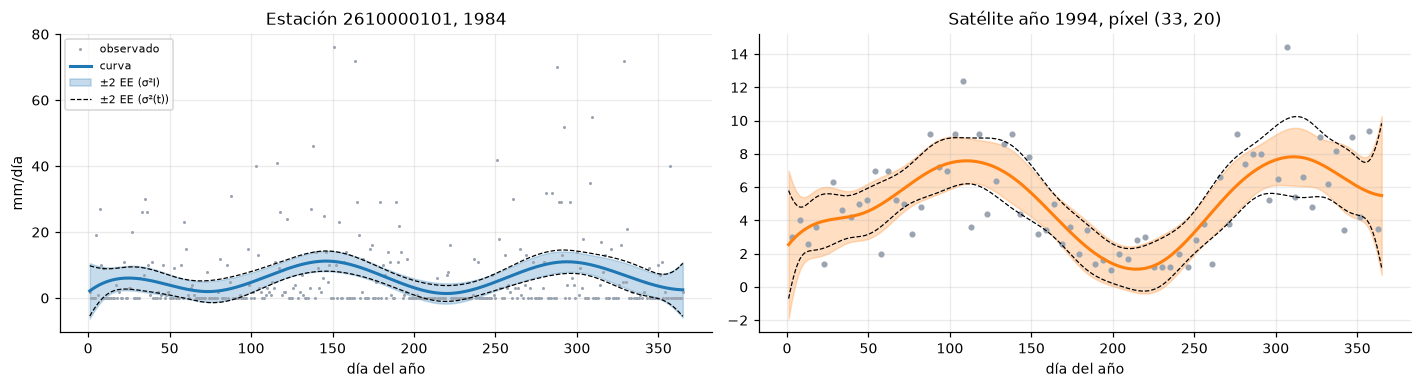

Ancho medio de la banda (±2 EE) — estación: σ²I 6.56, σ²(t) 6.50 | satélite: σ²I 3.27, σ²(t) 3.18  [mm/día]
Banda σ²(t) de la estación: más ancha el día 365, más angosta el día 189


In [14]:
def banda(Phi_eval, Phi_obs_C, Sigma):
    # EE punto a punto: sqrt(diag(Φ_eval C Σ Cᵀ Φ_evalᵀ)), con C ya restringido a los puntos observados
    M = Phi_eval @ Phi_obs_C
    return np.sqrt(np.einsum("ij,jk,ik->i", M, Sigma, M))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
i = i_ej; y = Y[i]
# forma estacional de la varianza (común a todas las curvas), escalada al σ̂² propio de cada curva
v_est = (Res_est ** 2).mean(0) / (1 - np.diag(H_est)); forma_est = v_est / v_est.mean()
v_sat = (Res_sat ** 2).mean(0) / (1 - np.diag(H_sat)); forma_sat = v_sat / v_sat.mean()
sig2_t_est = sig2_est[i] * forma_est
ee_iid = banda(Phi_est, C_est, sig2_est[i] * np.eye(365)); ee_gen = banda(Phi_est, C_est, np.diag(sig2_t_est))
ax[0].plot(t_est, y, ".", ms=2, c="#9aa5b1", label="observado")
ax[0].plot(t_est, F_est[i], c="C0", lw=2, label="curva")
ax[0].fill_between(t_est, F_est[i] - 2 * ee_iid, F_est[i] + 2 * ee_iid, alpha=.25, color="C0", label="±2 EE (σ²I)")
ax[0].plot(t_est, F_est[i] + 2 * ee_gen, "k--", lw=.8, label="±2 EE (σ²(t))"); ax[0].plot(t_est, F_est[i] - 2 * ee_gen, "k--", lw=.8)
ax[0].set(title=f"Estación {Y_mm.index[i][0]}, {Y_mm.index[i][1]}", xlabel="día del año", ylabel="mm/día"); ax[0].legend(fontsize=7)

j = 20000; Phi_eval_sat = base_bspline(t_est, RANGO, K_SAT)
ee_iid_s = banda(Phi_eval_sat, C_sat, sig2_sat[j] * np.eye(72)); ee_gen_s = banda(Phi_eval_sat, C_sat, np.diag(sig2_sat[j] * forma_sat))
ax[1].plot(t_sat, X[j], "o", ms=3, c="#9aa5b1"); ax[1].plot(t_est, F_sat[j], c="C1", lw=2)
ax[1].fill_between(t_est, F_sat[j] - 2 * ee_iid_s, F_sat[j] + 2 * ee_iid_s, alpha=.25, color="C1")
ax[1].plot(t_est, F_sat[j] + 2 * ee_gen_s, "k--", lw=.8); ax[1].plot(t_est, F_sat[j] - 2 * ee_gen_s, "k--", lw=.8)
ax[1].set(title=f"Satélite año {idx_sat[j][0]}, píxel {idx_sat[j][1:]}", xlabel="día del año")
plt.tight_layout(); plt.show()
print(f"Ancho medio de la banda (±2 EE) — estación: σ²I {4*ee_iid.mean():.2f}, σ²(t) {4*ee_gen.mean():.2f} | "
      f"satélite: σ²I {4*ee_iid_s.mean():.2f}, σ²(t) {4*ee_gen_s.mean():.2f}  [mm/día]")
print(f"Banda σ²(t) de la estación: más ancha el día {t_est[ee_gen.argmax()]:.0f}, más angosta el día {t_est[ee_gen.argmin()]:.0f}")

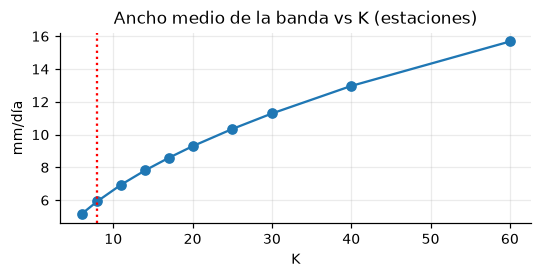

In [15]:
# Compromiso sesgo‑varianza: ancho medio de la banda σ²I vs K (estaciones completas, como en clase)
anchos = []
for K in [6, 8, 11, 14, 17, 20, 25, 30, 40, 60]:
    P = base_bspline(t_est, RANGO, K); C = np.linalg.solve(P.T @ P, P.T); H = P @ C
    s2 = ((Yc - Yc @ H.T) ** 2).sum(1) / (365 - K)
    anchos.append({"K": K, "ancho_medio": 4 * np.sqrt(np.mean(np.diag(H)) * s2).mean()})
anchos = pd.DataFrame(anchos)
fig, ax = plt.subplots(figsize=(5, 2.6)); ax.plot(anchos.K, anchos.ancho_medio, "o-"); ax.axvline(K_EST, c="r", ls=":")
ax.set(title="Ancho medio de la banda vs K (estaciones)", xlabel="K", ylabel="mm/día"); plt.tight_layout(); plt.show()

**Lectura de las bandas y de la covarianza residual.**

- Las bandas son **punto a punto**: en cada día t, el intervalo cubre el valor de la curva *en ese día* con ≈95 % de confianza. **No** son bandas simultáneas: no garantizan que la curva completa esté dentro de la banda a la vez en todos los días.
- **Estaciones:** la correlación residual entre días distintos es casi nula, con una correlación pequeña y positiva entre días consecutivos (lluvias que duran varios días). El supuesto de independencia es aceptable. La **varianza del error no es constante**: es mucho mayor en las temporadas de lluvia (abril‑mayo y octubre‑noviembre), cuando la lluvia diaria es más variable. Por eso la banda con σ²(t) se ensancha en esas temporadas y se estrecha en la temporada seca de julio‑agosto (en los extremos del año también se ensancha por el efecto de borde de la base). La banda σ²I, con ancho casi uniforme, subestima la incertidumbre en las temporadas lluviosas y la sobreestima en las secas.
- **Satélite:** la correlación residual es baja; el patrón de bandas alrededor de la diagonal lo induce la propia proyección (I − H) con solo 72 puntos. La varianza del error también es mayor en las temporadas lluviosas, sobre todo octubre‑noviembre.
- **Compromiso sesgo‑varianza:** con más bases la banda se ensancha (cada coeficiente se estima con menos datos); con pocas bases la curva es estable pero sesgada (aplana los picos). El K elegido por VCG equilibra ambas cosas.

## 7. Ambas fuentes sobre el mismo dominio anual

Las curvas se evalúan en los mismos días t = 1, …, 365. Todavía **no** se comparan estación y píxel emparejados (faltan las coordenadas, ver notebook 02); aquí solo se muestra que las dos construcciones son comparables. La curva media se lleva de vuelta a mm/día elevando al cuadrado.

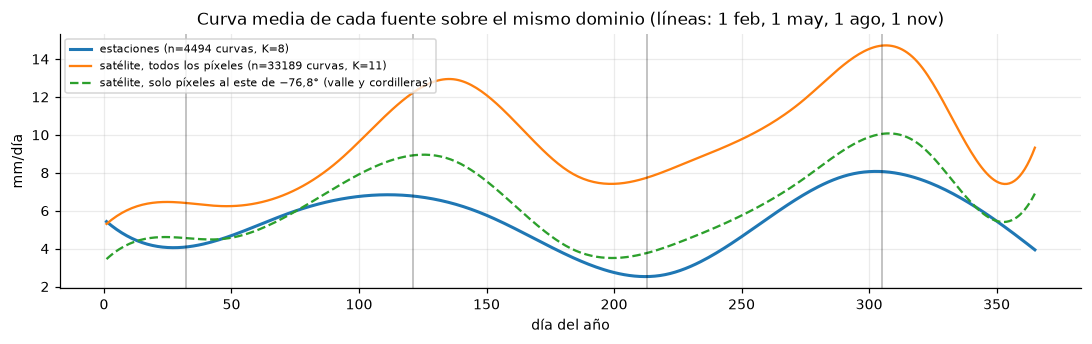

Máximos locales de la media — estaciones: [111, 303] | satélite (todo): [25, 135, 307] | satélite (valle): [24, 125, 308]
Media anual: estaciones 1971 mm | satélite todo 3481 mm | satélite valle 2316 mm


In [16]:
m_est = F_est.mean(0); m_sat = F_sat.mean(0)
oeste = (np.arange(W_) * .05 - 77.55 + .025) < -76.8
m_sat_valle = F_sat.reshape(n_an, H_, W_, 365)[:, :, ~oeste].mean((0, 1, 2))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_est, m_est, lw=2, label=f"estaciones (n={len(F_est)} curvas, K={K_EST})")
ax.plot(t_est, m_sat, label=f"satélite, todos los píxeles (n={len(F_sat)} curvas, K={K_SAT})")
ax.plot(t_est, m_sat_valle, "--", label="satélite, solo píxeles al este de −76,8° (valle y cordilleras)")
for d in [32, 121, 213, 305]: ax.axvline(d, c="k", lw=.3)
ax.set(title="Curva media de cada fuente sobre el mismo dominio (líneas: 1 feb, 1 may, 1 ago, 1 nov)", xlabel="día del año", ylabel="mm/día")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()
pk = lambda f: [int(t_est[i]) for i in range(1, 364) if f[i] > f[i - 1] and f[i] > f[i + 1]]
print("Máximos locales de la media — estaciones:", pk(m_est), "| satélite (todo):", pk(m_sat), "| satélite (valle):", pk(m_sat_valle))
print(f"Media anual: estaciones {m_est.mean()*365:.0f} mm | satélite todo {m_sat.mean()*365:.0f} mm | satélite valle {m_sat_valle.mean()*365:.0f} mm")

**Lectura.** Las dos fuentes, construidas por separado y con K distinto, muestran el **régimen bimodal** sobre el mismo dominio: un pico en abril‑mayo, otro en octubre‑noviembre y mínimos en enero‑febrero y julio‑agosto. El nivel del satélite completo es mucho mayor porque promedia la costa Pacífica (>5 000 mm/año), mientras que la mayoría de las estaciones están en el valle. Restringido a los píxeles del valle, el nivel se acerca al de las estaciones. La comparación justa (estación contra su píxel) se hace en la fase 3, con el emparejamiento.

Dos observaciones para las fases siguientes:
- Aun sin emparejar, el satélite del valle queda **por encima** de las estaciones en las dos temporadas de lluvia y muy cerca de ellas en la temporada seca de julio‑agosto. Es un primer indicio de que el sesgo satelital depende de la época del año.
- La caída de la curva de estaciones hacia el día 365 es un **efecto de borde**: con K = 8 la base no es periódica y el extremo queda poco determinado (los datos de diciembre no "ven" a los de enero). La banda también se ensancha allí. Si en la fase 2 (derivadas, inicio y fin de temporadas) molesta, la alternativa es una base periódica o repetir unos días de diciembre antes del 1 de enero y de enero después del 31 de diciembre.

In [17]:
# Guardar la construcción para las fases siguientes
spec = {"rango": RANGO, "orden": ORDEN, "K_estaciones": K_EST, "K_satelite": K_SAT,
        "nodos_estaciones": nodos(RANGO, K_EST).tolist(), "nodos_satelite": nodos(RANGO, K_SAT).tolist(),
        "escala": "mm/dia (la raiz se aplica despues, en la fase 4)", "dominio": "dia del año 1..365 (29-feb eliminado); péntadas en su día central"}
(OUT / "base_especificacion.json").write_text(json.dumps(spec, indent=2, ensure_ascii=False))
np.savez_compressed(OUT / "coeficientes_estaciones.npz", coef=coef_est, sigma2=sig2_est,
                    station_id=Y_mm.index.get_level_values(0).values, anio=Y_mm.index.get_level_values(1).values)
np.savez_compressed(OUT / "coeficientes_satelite.npz", coef=coef_sat.astype("float32"), sigma2=sig2_sat.astype("float32"),
                    anio=idx_sat.get_level_values(0).values, fila=idx_sat.get_level_values(1).values, col=idx_sat.get_level_values(2).values)
resumen.to_csv(OUT / "resumen_seleccion_K.csv", index=False)
# Matrices de curvas preparadas (mm/día) y coeficientes en CSV, para el script en R (03_construccion_funcional.R)
Y_mm.reset_index().to_csv(OUT / "curvas_estaciones_mm.csv.gz", index=False, float_format="%.4f")
pd.DataFrame(X_mm, index=idx_sat, columns=[f"t{v}" for v in t_sat]).reset_index().to_csv(OUT / "curvas_satelite_mm.csv.gz", index=False, float_format="%.5f")
pd.DataFrame(coef_est, index=Y_mm.index).reset_index().to_csv(OUT / "coef_estaciones.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['base_especificacion.json', 'coef_estaciones.csv', 'coef_estaciones_R.csv', 'coeficientes_estaciones.npz', 'coeficientes_satelite.npz', 'curvas_estaciones_mm.csv.gz', 'curvas_satelite_mm.csv.gz', 'figuras_R', 'resumen_seleccion_K.csv', 'seleccion_K_estaciones.csv', 'seleccion_K_satelite.csv']


## 8. Resumen para el informe (ítem 1)

| Requisito de la rúbrica | Dónde | Resultado |
|---|---|---|
| Φ y coeficientes por MCO paso a paso | §2–§3 | Cox–de Boor propia (= scipy a 1e‑16); ĉ = (ΦᵀΦ)⁻¹Φᵀy (= lstsq) |
| K con ECM, VC y VCG, por fuente | §4 | Gráficas y tabla; K elegido por VCG en mm/día para cada fuente (sensibilidad en √) |
| S idempotente y tr(S) = K | §3, §5 | Errores del orden de 1e‑15; traza = K también en curvas con faltantes |
| Covarianza residual y bandas punto a punto | §6 | Correlación residual casi nula; varianza mayor en temporadas de lluvia; bandas σ²I y σ²(t) |
| Ambas fuentes en el mismo dominio | §1, §7 | Día del año 1–365, mm/día, péntadas en su día central |

Salidas en `fda_fase1/`: especificación de la base, coeficientes de las 4 494 curvas de estaciones y de las 33 189 curvas satelitales (23 años × 1 443 píxeles, 1981–2003). K se eligió solo con curvas de entrenamiento (1981–1995): **K = 8 para estaciones y K = 11 para el satélite**, y las tablas de selección de K. El script equivalente en R (`03_construccion_funcional.R`) lee `curvas_*_mm.csv.gz`, repite todo con R base (sin `fda`) y verifica que sus coeficientes y K coinciden con los de Python.